In [4]:

import pandas as pd
import os

file_path = r"C:\Users\MY PC\Desktop\Banking-Credit-Risk-Analytics\data\raw\accepted_2007_to_2018Q4.csv"

print("File exists:", os.path.exists(file_path))


File exists: True


In [5]:

import os

folder_path = r"C:\Users\MY PC\Desktop\Banking-Credit-Risk-Analytics\data\raw"

print(os.listdir(folder_path))



['accepted_2007_to_2018q4.csv', 'accepted_2007_to_2018Q4.csv.gz', 'rejected_2007_to_2018q4.csv', 'rejected_2007_to_2018Q4.csv.gz']


In [6]:

import os

folder_path = r"C:\Users\MY PC\Desktop\Banking-Credit-Risk-Analytics\data\raw"

for name in os.listdir(folder_path):
    full_path = os.path.join(folder_path, name)
    print(name, "->", "Folder" if os.path.isdir(full_path) else "File")


accepted_2007_to_2018q4.csv -> Folder
accepted_2007_to_2018Q4.csv.gz -> File
rejected_2007_to_2018q4.csv -> Folder
rejected_2007_to_2018Q4.csv.gz -> File


In [7]:

import pandas as pd
import os

file_path = r"C:\Users\MY PC\Desktop\Banking-Credit-Risk-Analytics\data\raw\accepted_2007_to_2018Q4.csv.gz"

df = pd.read_csv(
    file_path,
    compression="gzip",
    nrows=1000,
    low_memory=False
)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (1000, 151)

First 5 rows:


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN



Column names:
['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'a

In [8]:

# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Data types and non-null counts
print("\nDataset Information:")
df.info()

# 3. Missing values in each column
print("\nTop 20 Columns with Missing Values:")
print(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .head(20)
)

# 4. Loan status distribution
print("\nLoan Status Distribution:")
print(df["loan_status"].value_counts(dropna=False))


Dataset Shape: (1000, 151)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Columns: 151 entries, id to settlement_term
dtypes: float64(115), int64(1), str(35)
memory usage: 1.4 MB

Top 20 Columns with Missing Values:
member_id                                     1000
desc                                          1000
sec_app_open_act_il                           1000
sec_app_inq_last_6mths                        1000
sec_app_open_acc                              1000
sec_app_mort_acc                              1000
sec_app_mths_since_last_major_derog           1000
sec_app_collections_12_mths_ex_med            1000
sec_app_chargeoff_within_12_mths              1000
sec_app_num_rev_accts                         1000
sec_app_earliest_cr_line                      1000
sec_app_revol_util                            1000
sec_app_fico_range_high                       1000
sec_app_fico_range_low                        1000
revol_bal_joint                  

In [9]:

# Select useful columns for initial credit risk analysis
selected_columns = [
    "id",
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "dti",
    "delinq_2yrs",
    "fico_range_low",
    "fico_range_high",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "loan_status"
]

credit_df = df[selected_columns].copy()

print("Selected dataset shape:", credit_df.shape)

display(credit_df.head())

print("\nMissing values:")
print(
    credit_df.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)


Selected dataset shape: (1000, 22)


,id,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,...,dti,delinq_2yrs,fico_range_low,fico_range_high,open_acc,pub_rec,revol_bal,revol_util,total_acc,loan_status
0,68407277,3600.0,36 months,13.99,123.03,C,C4,10+ years,MORTGAGE,55000.0,...,5.91,0.0,675.0,679.0,7.0,0.0,2765.0,29.7,13.0,Fully Paid
1,68355089,24700.0,36 months,11.99,820.28,C,C1,10+ years,MORTGAGE,65000.0,...,16.06,1.0,715.0,719.0,22.0,0.0,21470.0,19.2,38.0,Fully Paid
2,68341763,20000.0,60 months,10.78,432.66,B,B4,10+ years,MORTGAGE,63000.0,...,10.78,0.0,695.0,699.0,6.0,0.0,7869.0,56.2,18.0,Fully Paid
3,66310712,35000.0,60 months,14.85,829.90,C,C5,10+ years,MORTGAGE,110000.0,...,17.06,0.0,785.0,789.0,13.0,0.0,7802.0,11.6,17.0,Current
4,68476807,10400.0,60 months,22.45,289.91,F,F1,3 years,MORTGAGE,104433.0,...,25.37,1.0,695.0,699.0,12.0,0.0,21929.0,64.5,35.0,Fully Paid



Missing values:
emp_length        42
id                 0
term               0
int_rate           0
installment        0
loan_amnt          0
grade              0
sub_grade          0
home_ownership     0
annual_inc         0
dtype: int64


In [10]:

# Create a separate cleaned copy
credit_clean = credit_df.copy()

# Handle missing employment length
credit_clean["emp_length"] = (
    credit_clean["emp_length"].fillna("Unknown")
)

# Create a clear default-risk label
default_statuses = ["Charged Off", "Default"]
non_default_statuses = ["Fully Paid"]

credit_clean["risk_status"] = "Unresolved"

credit_clean.loc[
    credit_clean["loan_status"].isin(default_statuses),
    "risk_status"
] = "Default"

credit_clean.loc[
    credit_clean["loan_status"].isin(non_default_statuses),
    "risk_status"
] = "Non-Default"

# Check the results
print("Missing employment length:",
      credit_clean["emp_length"].isnull().sum())

print("\nLoan status counts:")
print(credit_clean["loan_status"].value_counts())

print("\nRisk status counts:")
print(credit_clean["risk_status"].value_counts())

display(
    credit_clean[
        ["loan_status", "risk_status", "emp_length"]
    ].head(10)
)


Missing employment length: 0

Loan status counts:
loan_status
Fully Paid            728
Charged Off           145
Current               121
Late (31-120 days)      5
In Grace Period         1
Name: count, dtype: int64

Risk status counts:
risk_status
Non-Default    728
Default        145
Unresolved     127
Name: count, dtype: int64


,loan_status,risk_status,emp_length
0,Fully Paid,Non-Default,10+ years
1,Fully Paid,Non-Default,10+ years
2,Fully Paid,Non-Default,10+ years
3,Current,Unresolved,10+ years
4,Fully Paid,Non-Default,3 years
5,Fully Paid,Non-Default,4 years
6,Fully Paid,Non-Default,10+ years
7,Fully Paid,Non-Default,10+ years
8,Fully Paid,Non-Default,6 years
9,Fully Paid,Non-Default,10+ years


In [11]:

# Keep only resolved loan outcomes for default-rate analysis
resolved_loans = credit_clean[
    credit_clean["risk_status"].isin(
        ["Default", "Non-Default"]
    )
].copy()

total_resolved = len(resolved_loans)
default_loans = (
    resolved_loans["risk_status"] == "Default"
).sum()
non_default_loans = (
    resolved_loans["risk_status"] == "Non-Default"
).sum()

default_rate = default_loans / total_resolved * 100

print("Total Resolved Loans:", total_resolved)
print("Default Loans:", default_loans)
print("Non-Default Loans:", non_default_loans)
print(f"Default Rate: {default_rate:.2f}%")


Total Resolved Loans: 873
Default Loans: 145
Non-Default Loans: 728
Default Rate: 16.61%


In [12]:

grade_analysis = (
    resolved_loans
    .groupby("grade")
    .agg(
        total_loans=("id", "count"),
        default_loans=("risk_status",
                       lambda x: (x == "Default").sum()),
        avg_loan_amount=("loan_amnt", "mean"),
        avg_interest_rate=("int_rate", "mean")
    )
    .reset_index()
)

grade_analysis["default_rate_pct"] = (
    grade_analysis["default_loans"]
    / grade_analysis["total_loans"] * 100
)

grade_analysis = grade_analysis.sort_values(
    "default_rate_pct", ascending=False
)

display(grade_analysis.round(2))


,grade,total_loans,default_loans,avg_loan_amount,avg_interest_rate,default_rate_pct
6,G,4,3,19525.00,27.74,75.00
4,E,44,17,17240.34,19.68,38.64
3,D,118,35,16567.16,17.01,29.66
5,F,16,4,21240.62,23.56,25.00
2,C,228,49,15293.20,13.26,21.49
1,B,253,32,13282.21,9.94,12.65
0,A,210,5,14523.81,6.64,2.38


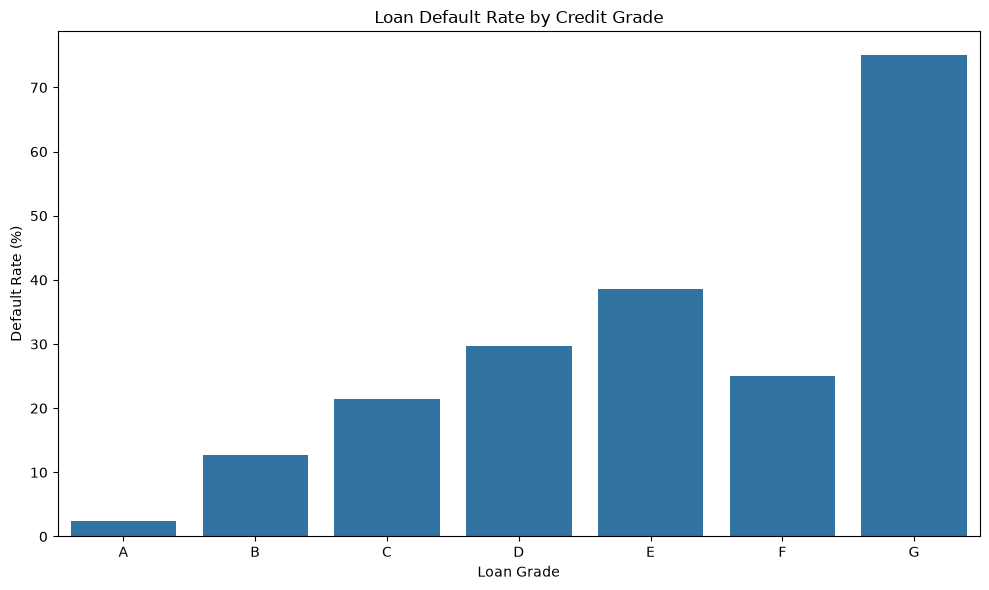

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Sort grades in their natural order
plot_data = grade_analysis.sort_values("grade")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="grade",
    y="default_rate_pct"
)

plt.title("Loan Default Rate by Credit Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()


In [14]:

# Analyze interest rate against loan default

interest_analysis = (
    resolved_loans
    .assign(
        interest_band=pd.cut(
            resolved_loans["int_rate"],
            bins=[0, 8, 12, 16, 20, 30],
            labels=[
                "0-8%",
                "8-12%",
                "12-16%",
                "16-20%",
                "20%+"
            ],
            include_lowest=True
        )
    )
    .groupby("interest_band", observed=False)
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

interest_analysis["default_rate_pct"] = (
    interest_analysis["default_loans"]
    / interest_analysis["total_loans"].replace(0, pd.NA)
    * 100
)

print("Interest Rate vs Default Analysis")
display(interest_analysis.round(2))


Interest Rate vs Default Analysis


,interest_band,total_loans,default_loans,avg_loan_amount,default_rate_pct
0,0-8%,210,5,14523.81,2.38
1,8-12%,305,40,13545.57,13.11
2,12-16%,205,48,15651.22,23.41
3,16-20%,125,40,16368.60,32.00
4,20%+,28,12,21168.75,42.86


In [15]:
dti_analysis = (
    resolved_loans
    .assign(
        dti_band=pd.cut(
            resolved_loans["dti"],
            bins=[-float("inf"), 10, 20, 30, 40, float("inf")],
            labels=["0-10", "10-20", "20-30", "30-40", "40+"]
        )
    )
    .groupby("dti_band", observed=False)
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

dti_analysis["default_rate_pct"] = (
    dti_analysis["default_loans"]
    / dti_analysis["total_loans"].replace(0, float("nan"))
    * 100
)

print("DTI vs Default Analysis")
display(dti_analysis.round(2))

DTI vs Default Analysis


,dti_band,total_loans,default_loans,avg_loan_amount,default_rate_pct
0,0-10,117,13,13847.44,11.11
1,10-20,382,53,15367.60,13.87
2,20-30,275,53,15120.09,19.27
3,30-40,98,25,13993.37,25.51
4,40+,1,1,8750.00,100.00


In [16]:
fico_analysis_df = resolved_loans.copy()

fico_analysis_df["avg_fico_score"] = (
    fico_analysis_df["fico_range_low"]
    + fico_analysis_df["fico_range_high"]
) / 2

fico_analysis_df["fico_band"] = pd.cut(
    fico_analysis_df["avg_fico_score"],
    bins=[0, 580, 670, 740, 800, 851],
    labels=["Below 580", "580-669", "670-739", "740-799", "800+"],
    right=False
)

fico_analysis = (
    fico_analysis_df
    .groupby("fico_band", observed=False)
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

fico_analysis["default_rate_pct"] = (
    fico_analysis["default_loans"]
    / fico_analysis["total_loans"].replace(0, float("nan"))
    * 100
)

print("FICO Score vs Default Analysis")
display(fico_analysis.round(2))

FICO Score vs Default Analysis


,fico_band,total_loans,default_loans,avg_loan_amount,default_rate_pct
0,Below 580,0,0,NaN,NaN
1,580-669,137,37,12543.61,27.01
2,670-739,618,103,15578.72,16.67
3,740-799,104,5,14115.38,4.81
4,800+,14,0,15326.79,0.00


In [17]:
purpose_analysis = (
    resolved_loans
    .groupby("purpose")
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

purpose_analysis["default_rate_pct"] = (
    purpose_analysis["default_loans"]
    / purpose_analysis["total_loans"]
    * 100
)

purpose_analysis = purpose_analysis.sort_values(
    "default_rate_pct",
    ascending=False
)

print("Loan Purpose vs Default Analysis")
display(purpose_analysis.round(2))

Loan Purpose vs Default Analysis


,purpose,total_loans,default_loans,avg_loan_amount,default_rate_pct
4,house,5,2,11515.00,40.00
6,medical,3,1,6450.00,33.33
9,small_business,9,2,12227.78,22.22
0,car,10,2,11042.50,20.00
2,debt_consolidation,497,96,15504.48,19.32
8,other,44,7,10396.59,15.91
5,major_purchase,21,3,13347.62,14.29
3,home_improvement,50,7,14766.50,14.00
1,credit_card,226,25,15371.68,11.06
7,moving,4,0,14500.00,0.00


In [18]:
employment_analysis = (
    resolved_loans
    .groupby("emp_length")
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

employment_analysis["default_rate_pct"] = (
    employment_analysis["default_loans"]
    / employment_analysis["total_loans"]
    * 100
)

employment_analysis = employment_analysis.sort_values(
    "default_rate_pct",
    ascending=False
)

print("Employment Length vs Default Analysis")
display(employment_analysis.round(2))

Employment Length vs Default Analysis


,emp_length,total_loans,default_loans,avg_loan_amount,default_rate_pct
9,9 years,21,6,17992.86,28.57
0,1 year,60,15,14655.42,25.00
5,5 years,56,14,14898.66,25.00
2,2 years,85,19,13172.94,22.35
6,6 years,30,6,16468.33,20.00
7,7 years,24,4,14409.38,16.67
8,8 years,38,6,15536.84,15.79
1,10+ years,307,47,15570.68,15.31
10,< 1 year,81,11,16095.68,13.58
4,4 years,53,6,15319.34,11.32


In [19]:
overall_risk_summary = pd.DataFrame({
    "Metric": [
        "Total Resolved Loans",
        "Total Default Loans",
        "Total Non-Default Loans",
        "Overall Default Rate (%)",
        "Average Loan Amount",
        "Average Interest Rate (%)",
        "Average DTI",
        "Average Annual Income",
        "Average FICO Score"
    ],
    "Value": [
        len(resolved_loans),
        (resolved_loans["risk_status"] == "Default").sum(),
        (resolved_loans["risk_status"] == "Non-Default").sum(),
        (resolved_loans["risk_status"] == "Default").mean() * 100,
        resolved_loans["loan_amnt"].mean(),
        resolved_loans["int_rate"].mean(),
        resolved_loans["dti"].mean(),
        resolved_loans["annual_inc"].mean(),
        (
            resolved_loans["fico_range_low"]
            .add(resolved_loans["fico_range_high"])
            .div(2)
            .mean()
        )
    ]
})

print("Overall Credit Risk Summary")
display(overall_risk_summary.round(2))

Overall Credit Risk Summary


,Metric,Value
0,Total Resolved Loans,873.00
1,Total Default Loans,145.00
2,Total Non-Default Loans,728.00
3,Overall Default Rate (%),16.61
4,Average Loan Amount,14924.05
5,Average Interest Rate (%),11.79
6,Average DTI,19.14
7,Average Annual Income,79421.28
8,Average FICO Score,701.46


In [1]:
import pandas as pd

file_path = r"C:\Users\MY PC\Desktop\Banking-Credit-Risk-Analytics\data\raw\accepted_2007_to_2018Q4.csv.gz"

df_full = pd.read_csv(
    file_path,
    compression="gzip",
    low_memory=False
)

print("Full Dataset Shape:", df_full.shape)
print("Total Rows:", len(df_full))
print("Total Columns:", len(df_full.columns))

Full Dataset Shape: (2260701, 151)
Total Rows: 2260701
Total Columns: 151


In [2]:
selected_columns = [
    "id", "loan_amnt", "term", "int_rate", "installment",
    "grade", "sub_grade", "emp_length", "home_ownership",
    "annual_inc", "verification_status", "purpose", "dti",
    "delinq_2yrs", "fico_range_low", "fico_range_high",
    "open_acc", "pub_rec", "revol_bal", "revol_util",
    "total_acc", "loan_status"
]

credit_df_full = df_full[selected_columns].copy()

print("Selected Dataset Shape:", credit_df_full.shape)

print("\nMissing Values:")
display(
    credit_df_full.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Selected Dataset Shape: (2260701, 22)

Missing Values:


emp_length             146940
revol_util               1835
dti                      1744
delinq_2yrs                62
total_acc                  62
open_acc                   62
pub_rec                    62
annual_inc                 37
verification_status        33
grade                      33
dtype: int64

In [3]:
credit_clean_full = credit_df_full.copy()

# Fill missing employment length
credit_clean_full["emp_length"] = (
    credit_clean_full["emp_length"].fillna("Unknown")
)

# Define loan risk status
default_statuses = ["Charged Off", "Default"]
non_default_statuses = ["Fully Paid"]

credit_clean_full["risk_status"] = "Unresolved"

credit_clean_full.loc[
    credit_clean_full["loan_status"].isin(default_statuses),
    "risk_status"
] = "Default"

credit_clean_full.loc[
    credit_clean_full["loan_status"].isin(non_default_statuses),
    "risk_status"
] = "Non-Default"

# Check loan status distribution
print("Loan Status Distribution:")
display(
    credit_clean_full["loan_status"]
    .value_counts(dropna=False)
)

print("\nRisk Status Distribution:")
display(
    credit_clean_full["risk_status"]
    .value_counts(dropna=False)
)

Loan Status Distribution:


loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
NaN                                                         33
Name: count, dtype: int64


Risk Status Distribution:


risk_status
Non-Default    1076751
Unresolved      915351
Default         268599
Name: count, dtype: int64

In [4]:
resolved_loans_full = credit_clean_full[
    credit_clean_full["risk_status"].isin(
        ["Default", "Non-Default"]
    )
].copy()

total_resolved = len(resolved_loans_full)

total_defaults = (
    resolved_loans_full["risk_status"] == "Default"
).sum()

total_non_defaults = (
    resolved_loans_full["risk_status"] == "Non-Default"
).sum()

default_rate = total_defaults / total_resolved * 100

print("Full Dataset Credit Risk Summary")
print("-" * 35)
print("Total Resolved Loans:", total_resolved)
print("Total Default Loans:", total_defaults)
print("Total Non-Default Loans:", total_non_defaults)
print("Overall Default Rate (%):", round(default_rate, 2))

Full Dataset Credit Risk Summary
-----------------------------------
Total Resolved Loans: 1345350
Total Default Loans: 268599
Total Non-Default Loans: 1076751
Overall Default Rate (%): 19.96


In [5]:
grade_analysis_full = (
    resolved_loans_full
    .groupby("grade")
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean"),
        avg_interest_rate=("int_rate", "mean")
    )
    .reset_index()
)

grade_analysis_full["default_rate_pct"] = (
    grade_analysis_full["default_loans"]
    / grade_analysis_full["total_loans"]
    * 100
)

grade_analysis_full = grade_analysis_full.sort_values(
    "default_rate_pct",
    ascending=False
)

print("Full Dataset: Grade vs Default Analysis")
display(grade_analysis_full.round(2))

Full Dataset: Grade vs Default Analysis


,grade,total_loans,default_loans,avg_loan_amount,avg_interest_rate,default_rate_pct
6,G,9132,4560,20588.81,27.73,49.93
5,F,32059,14492,19087.68,24.93,45.20
4,E,93656,36041,17618.25,21.14,38.48
3,D,200966,61067,15272.27,17.72,30.39
2,C,381694,85657,14188.39,14.02,22.44
1,B,392748,52576,13237.62,10.68,13.39
0,A,235095,14206,13892.34,7.11,6.04


In [6]:
interest_analysis_full = (
    resolved_loans_full
    .assign(
        interest_band=pd.cut(
            resolved_loans_full["int_rate"],
            bins=[0, 8, 12, 16, 20, float("inf")],
            labels=["0-8%", "8-12%", "12-16%", "16-20%", "20%+"],
            include_lowest=True,
            right=False
        )
    )
    .groupby("interest_band", observed=False)
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

interest_analysis_full["default_rate_pct"] = (
    interest_analysis_full["default_loans"]
    / interest_analysis_full["total_loans"].replace(0, float("nan"))
    * 100
)

print("Full Dataset: Interest Rate vs Default Analysis")
display(interest_analysis_full.round(2))

Full Dataset: Interest Rate vs Default Analysis


,interest_band,total_loans,default_loans,avg_loan_amount,default_rate_pct
0,0-8%,208234,12131,13901.26,5.83
1,8-12%,382519,51016,13321.58,13.34
2,12-16%,419707,90516,13991.79,21.57
3,16-20%,224736,70162,15738.01,31.22
4,20%+,110154,44774,18157.17,40.65


In [8]:
dti_analysis_full = (
    resolved_loans_full
    .assign(
        dti_band=pd.cut(
            resolved_loans_full["dti"],
            bins=[-float("inf"), 10, 20, 30, 40, float("inf")],
            labels=["0-10", "10-20", "20-30", "30-40", "40+"]
        )
    )
    .groupby("dti_band", observed=False)
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

dti_analysis_full["default_rate_pct"] = (
    dti_analysis_full["default_loans"]
    / dti_analysis_full["total_loans"].replace(0, float("nan"))
    * 100
)

print("Full Dataset: DTI vs Default Analysis")
display(dti_analysis_full.round(2))

Full Dataset: DTI vs Default Analysis


,dti_band,total_loans,default_loans,avg_loan_amount,default_rate_pct
0,0-10,246188,36646,13549.21,14.89
1,10-20,562128,100322,14620.90,17.85
2,20-30,408353,94122,14710.75,23.05
3,30-40,121541,35371,14102.88,29.10
4,40+,6766,2067,17398.28,30.55


In [9]:
fico_analysis_df_full = resolved_loans_full.copy()

fico_analysis_df_full["avg_fico_score"] = (
    fico_analysis_df_full["fico_range_low"]
    + fico_analysis_df_full["fico_range_high"]
) / 2

fico_analysis_df_full["fico_band"] = pd.cut(
    fico_analysis_df_full["avg_fico_score"],
    bins=[0, 580, 670, 740, 800, 851],
    labels=["Below 580", "580-669", "670-739", "740-799", "800+"],
    right=False
)

fico_analysis_full = (
    fico_analysis_df_full
    .groupby("fico_band", observed=False)
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

fico_analysis_full["default_rate_pct"] = (
    fico_analysis_full["default_loans"]
    / fico_analysis_full["total_loans"].replace(0, float("nan"))
    * 100
)

print("Full Dataset: FICO Score vs Default Analysis")
display(fico_analysis_full.round(2))

Full Dataset: FICO Score vs Default Analysis


,fico_band,total_loans,default_loans,avg_loan_amount,default_rate_pct
0,Below 580,0,0,NaN,NaN
1,580-669,237692,62463,12623.84,26.28
2,670-739,962355,192104,14725.59,19.96
3,740-799,129855,13040,15325.18,10.04
4,800+,15448,992,15408.29,6.42


In [10]:
purpose_analysis_full = (
    resolved_loans_full
    .groupby("purpose")
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

purpose_analysis_full["default_rate_pct"] = (
    purpose_analysis_full["default_loans"]
    / purpose_analysis_full["total_loans"]
    * 100
)

purpose_analysis_full = purpose_analysis_full.sort_values(
    "default_rate_pct",
    ascending=False
)

print("Full Dataset: Loan Purpose vs Default Analysis")
display(purpose_analysis_full.round(2))

Full Dataset: Loan Purpose vs Default Analysis


,purpose,total_loans,default_loans,avg_loan_amount,default_rate_pct
11,small_business,15416,4580,15641.61,29.71
10,renewable_energy,933,221,10018.27,23.69
8,moving,9480,2214,7863.45,23.35
5,house,7254,1588,15401.42,21.89
7,medical,15556,3389,9001.96,21.79
2,debt_consolidation,780342,165035,15232.38,21.15
9,other,77877,16387,9829.49,21.04
12,vacation,9065,1738,6192.34,19.17
6,major_purchase,29427,5475,11838.50,18.61
4,home_improvement,87507,15505,14144.86,17.72


In [11]:

employment_analysis_full = (
    resolved_loans_full
    .groupby("emp_length")
    .agg(
        total_loans=("id", "count"),
        default_loans=(
            "risk_status",
            lambda x: (x == "Default").sum()
        ),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

employment_analysis_full["default_rate_pct"] = (
    employment_analysis_full["default_loans"]
    / employment_analysis_full["total_loans"] * 100
)

employment_analysis_full = employment_analysis_full.sort_values(
    "default_rate_pct",
    ascending=False
)

print("Full Dataset: Employment Length vs Default Analysis")
display(employment_analysis_full.round(2))


Full Dataset: Employment Length vs Default Analysis


,emp_length,total_loans,default_loans,avg_loan_amount,default_rate_pct
11,Unknown,78516,21135,11495.38,26.92
0,1 year,88495,18199,13472.69,20.57
10,< 1 year,108065,22186,13796.84,20.53
3,3 years,107602,21491,13874.86,19.97
8,8 years,60704,12103,14722.31,19.94
9,9 years,50937,10137,14832.37,19.90
2,2 years,121751,24122,13760.53,19.81
4,4 years,80558,15902,14014.10,19.74
5,5 years,84154,16495,14152.54,19.60
7,7 years,59624,11620,14548.52,19.49


In [12]:

total_resolved_loans = len(resolved_loans_full)

total_defaults = (
    resolved_loans_full["risk_status"] == "Default"
).sum()

total_non_defaults = (
    resolved_loans_full["risk_status"] == "Non-Default"
).sum()

overall_default_rate = (
    total_defaults / total_resolved_loans
) * 100

avg_loan_amount = resolved_loans_full["loan_amnt"].mean()
avg_interest_rate = resolved_loans_full["int_rate"].mean()
avg_annual_income = resolved_loans_full["annual_inc"].mean()
avg_dti = resolved_loans_full["dti"].mean()

print("OVERALL CREDIT RISK SUMMARY")
print("-" * 40)
print(f"Total Resolved Loans: {total_resolved_loans:,}")
print(f"Total Defaults: {total_defaults:,}")
print(f"Total Non-Defaults: {total_non_defaults:,}")
print(f"Overall Default Rate: {overall_default_rate:.2f}%")
print(f"Average Loan Amount: {avg_loan_amount:,.2f}")
print(f"Average Interest Rate: {avg_interest_rate:.2f}%")
print(f"Average Annual Income: {avg_annual_income:,.2f}")
print(f"Average DTI: {avg_dti:.2f}")


OVERALL CREDIT RISK SUMMARY
----------------------------------------
Total Resolved Loans: 1,345,350
Total Defaults: 268,599
Total Non-Defaults: 1,076,751
Overall Default Rate: 19.96%
Average Loan Amount: 14,419.97
Average Interest Rate: 13.24%
Average Annual Income: 76,247.57
Average DTI: 18.28


In [13]:

# Keep resolved loans for credit risk analysis
credit_final = resolved_loans_full.copy()

# Export cleaned dataset
output_path = r"C:\Users\MY PC\Desktop\Banking-Credit-Risk-Analytics\data\processed\credit_risk_cleaned.csv"

credit_final.to_csv(output_path, index=False)

print("Cleaned dataset exported successfully!")
print("Rows:", len(credit_final))
print("Columns:", len(credit_final.columns))
print("Saved to:", output_path)


Cleaned dataset exported successfully!
Rows: 1345350
Columns: 23
Saved to: C:\Users\MY PC\Desktop\Banking-Credit-Risk-Analytics\data\processed\credit_risk_cleaned.csv


In [14]:

# Validate the exported analytical dataset

print("Dataset Shape:", credit_final.shape)

print("\nRisk Status Counts:")
print(credit_final["risk_status"].value_counts())

print("\nDuplicate Rows:", credit_final.duplicated().sum())

print("\nMissing Values:")
print(credit_final.isnull().sum().sort_values(ascending=False).head(10))

print("\nLoan Amount Summary:")
print(credit_final["loan_amnt"].describe().round(2))

print("\nDefault Rate Check:")
print(
    round(
        (credit_final["risk_status"] == "Default").mean() * 100,
        2
    ),
    "%"
)


Dataset Shape: (1345350, 23)

Risk Status Counts:
risk_status
Non-Default    1076751
Default         268599
Name: count, dtype: int64

Duplicate Rows: 0

Missing Values:
revol_util     857
dti            374
id               0
int_rate         0
installment      0
loan_amnt        0
term             0
sub_grade        0
grade            0
annual_inc       0
dtype: int64

Loan Amount Summary:
count    1345350.00
mean       14419.97
std         8717.10
min          500.00
25%         8000.00
50%        12000.00
75%        20000.00
max        40000.00
Name: loan_amnt, dtype: float64

Default Rate Check:
19.96 %


In [1]:

SELECT
    CASE
        WHEN int_rate < 8 THEN '0-8%'
        WHEN int_rate < 12 THEN '8-12%'
        WHEN int_rate < 16 THEN '12-16%'
        WHEN int_rate < 20 THEN '16-20%'
        ELSE '20%+'
    END AS interest_rate_band,

    COUNT(*) AS total_loans,

    COUNT(*) FILTER (
        WHERE risk_status = 'Default'
    ) AS default_loans,

    ROUND(
        COUNT(*) FILTER (
            WHERE risk_status = 'Default'
        ) * 100.0 / COUNT(*),
        2
    ) AS default_rate_pct,

    ROUND(AVG(loan_amnt), 2) AS avg_loan_amount

FROM public.credit_risk
WHERE int_rate IS NOT NULL
GROUP BY 1
ORDER BY
    MIN(int_rate);


IndentationError: unexpected indent (4007234913.py, line 2)